Pair: a2images/wadham.jpg + a2images/flag.png
[info] this OpenCV build has no GUI (headless). To get the click window: pip uninstall -y opencv-python-headless; pip install opencv-python  (then restart the kernel). Trying fallbacks...
  clicked points: [[158.8476104736328, 224.94515991210938], [503.44012451171875, 298.9374084472656], [502.3830871582031, 445.8648986816406], [158.8476104736328, 430.0094299316406]]  <- paste into PAIRS to reuse
H (own DLT):
 [[2.8325000e-01 7.1000000e-04 1.5884761e+02]
 [1.0012000e-01 2.1576000e-01 2.2494516e+02]
 [2.1000000e-04 0.0000000e+00 1.0000000e+00]]
max |H - H_opencv| = 4.548468268694705e-09


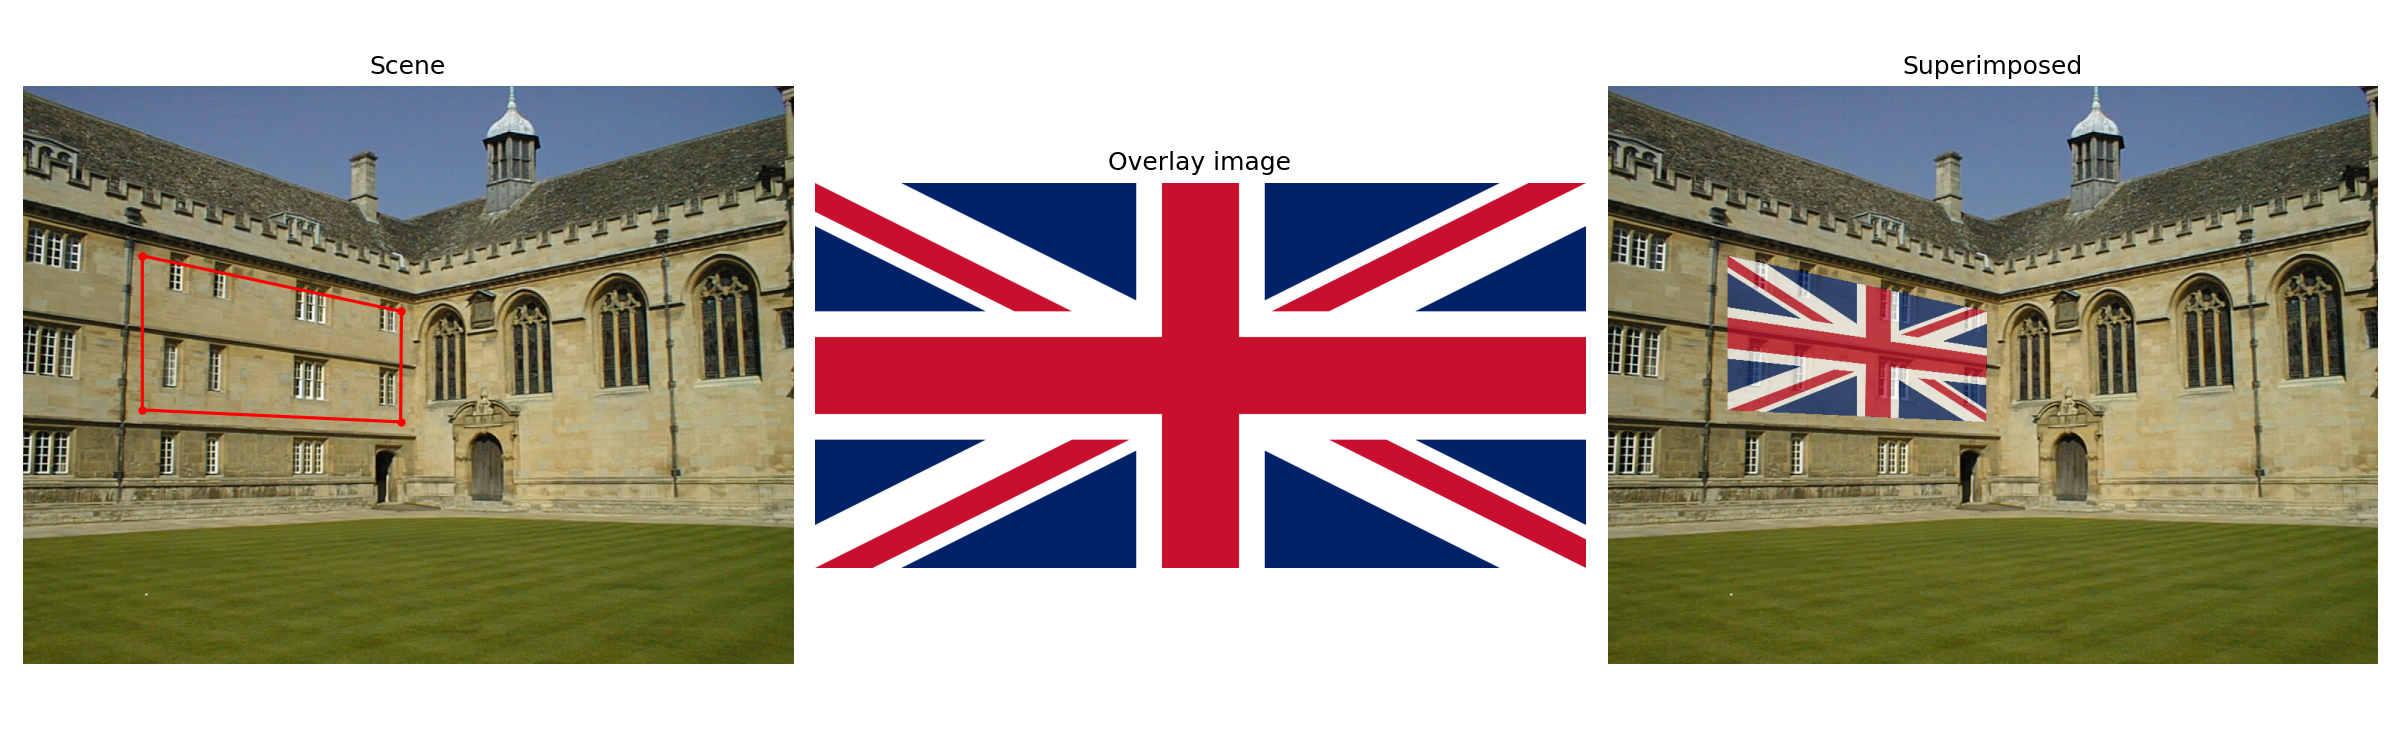

Pair: a2images/001.jpg + a2images/flag.png
[info] this OpenCV build has no GUI (headless). To get the click window: pip uninstall -y opencv-python-headless; pip install opencv-python  (then restart the kernel). Trying fallbacks...
  clicked points: [[585.888671875, 226.002197265625], [808.9224243164062, 186.89199829101562], [812.0935668945312, 362.3593444824219], [588.002685546875, 369.7585754394531]]  <- paste into PAIRS to reuse
H (own DLT):
 [[ 4.0000000e-02  8.8000000e-04  5.8588867e+02]
 [-3.7990000e-02  1.4907000e-01  2.2600220e+02]
 [-9.0000000e-05 -0.0000000e+00  1.0000000e+00]]
max |H - H_opencv| = 3.9474116420024075e-08


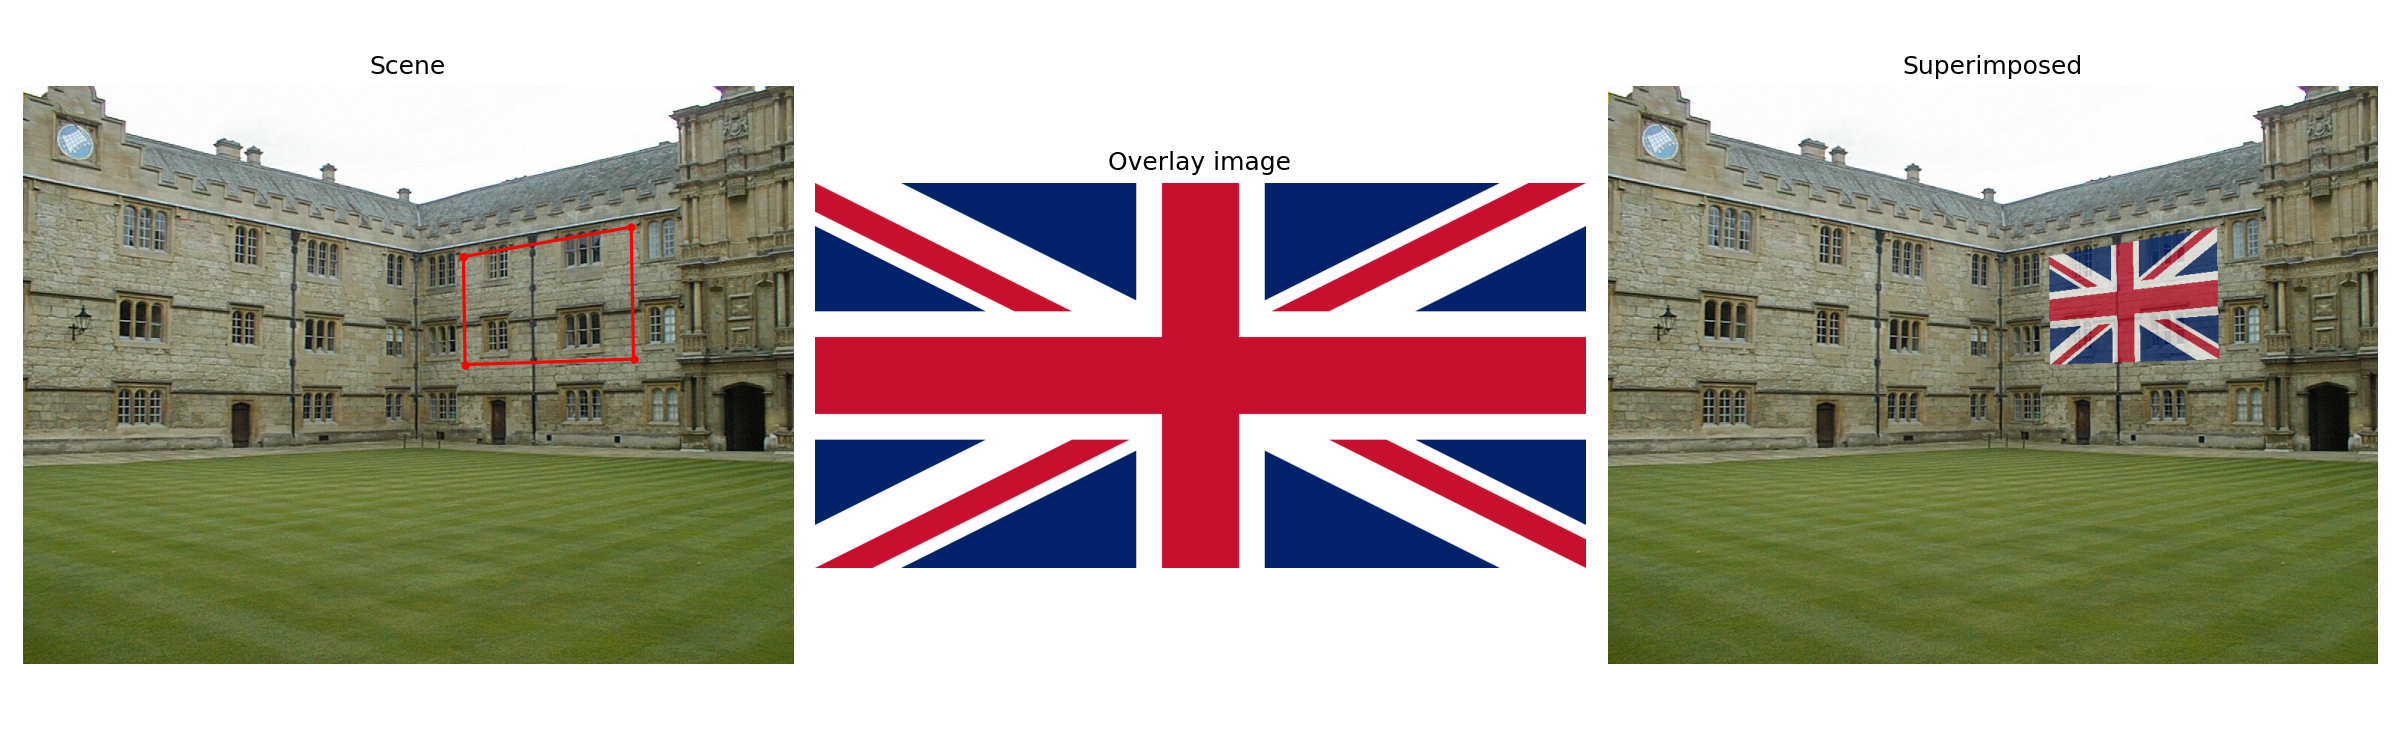

In [ ]:
# Question 3
import re
import sys
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
PAIRS = [
    ('a2images/wadham.jpg', 'a2images/flag.png', None, 'q3_result_1.png'),
    ('a2images/001.jpg',    'a2images/flag.png', None, 'q3_result_2.png'),
]
ALPHA = 0.7            
USE_SAVED_POINTS = False


def _display_file(path):
    try:
        from IPython import get_ipython
        from IPython.display import display, Image
        if get_ipython() is not None:
            display(Image(filename=path))
            return True
    except Exception:
        pass
    return False


def _click_opencv(img_bgr, title='Click 4 points: TL, TR, BR, BL  (Esc = cancel)'):
    pts = []
    disp = img_bgr.copy()

    def on_mouse(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(pts) < 4:
            pts.append([x, y])
            cv.circle(disp, (x, y), 6, (0, 0, 255), -1)
            cv.putText(disp, str(len(pts)), (x + 10, y - 10),
                       cv.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)

    cv.namedWindow(title, cv.WINDOW_NORMAL)       
    cv.setMouseCallback(title, on_mouse)
    while len(pts) < 4:
        cv.imshow(title, disp)
        if cv.waitKey(20) & 0xFF == 27:           
            break
    cv.imshow(title, disp)
    cv.waitKey(400)
    cv.destroyAllWindows()
    cv.waitKey(1)
    if len(pts) < 4:
        raise RuntimeError('Need 4 points')
    return np.array(pts, dtype=np.float32)


def _click_matplotlib_tk(img_bgr):
    old = plt.get_backend()
    pts = []
    try:
        plt.switch_backend('TkAgg')
        fig, ax = plt.subplots(1, 1, figsize=(10, 8))
        ax.imshow(cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB))
        ax.set_title('Click 4 points: TL, TR, BR, BL')
        pts = plt.ginput(4, timeout=120)          # gives up after 2 minutes
        plt.close(fig)
    finally:
        try:
            plt.switch_backend(old)
        except Exception:
            pass
    return np.array(pts, dtype=np.float32) if len(pts) == 4 else None


def _click_manual(img_bgr):
    h, w = img_bgr.shape[:2]
    fig, ax = plt.subplots(1, 1, figsize=(12, 9))
    ax.imshow(cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB))
    ax.set_xticks(np.arange(0, w, 50)); ax.set_yticks(np.arange(0, h, 50))
    ax.grid(True, color='yellow', alpha=0.5, lw=0.5)
    ax.tick_params(labelsize=6, labeltop=True, labelright=True)
    plt.setp(ax.get_xticklabels(), rotation=90)
    ax.set_title(f'Image {w}x{h}: read pixel coordinates (x right, y down)')
    fig.savefig('q3_pick_points.png', dpi=130)
    plt.close(fig)
    if not _display_file('q3_pick_points.png'):
        print('Open q3_pick_points.png to read the pixel coordinates.')
    s = input('Type 4 points as: x1,y1 x2,y2 x3,y3 x4,y4  (TL, TR, BR, BL): ')
    nums = re.findall(r'-?\d+\.?\d*', s)
    if len(nums) != 8:
        raise ValueError('Need exactly 8 numbers (4 points)')
    return np.array(nums, dtype=np.float32).reshape(4, 2)


def click_four_points(img_bgr):
    try:
        return _click_opencv(img_bgr)
    except cv.error:
        print('[info] this OpenCV build has no GUI (headless). '
              'To get the click window: pip uninstall -y opencv-python-headless; '
              'pip install opencv-python  (then restart the kernel). Trying fallbacks...')
    try:
        pts = _click_matplotlib_tk(img_bgr)
        if pts is not None:
            return pts
    except Exception as e:
        print('[info] matplotlib Tk window not available:', type(e).__name__)
    return _click_manual(img_bgr)



In [ ]:

def homography_dlt(src, dst):
    A = []
    for (x, y), (u, v) in zip(src, dst):
        A.append([-x, -y, -1, 0, 0, 0, u * x, u * y, u])
        A.append([0, 0, 0, -x, -y, -1, v * x, v * y, v])
    _, _, Vt = np.linalg.svd(np.asarray(A, dtype=np.float64))
    H = Vt[-1].reshape(3, 3)
    return H / H[2, 2]


def superimpose(scene, overlay, dst_pts, alpha=ALPHA):
    h, w = overlay.shape[:2]
    src_pts = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype=np.float32)

    H = homography_dlt(src_pts, dst_pts)
    # sanity check against OpenCV
    H_cv = cv.getPerspectiveTransform(src_pts, dst_pts.astype(np.float32))
    print('H (own DLT):\n', np.round(H, 5))
    print('max |H - H_opencv| =', np.abs(H - H_cv / H_cv[2, 2]).max())

    size = (scene.shape[1], scene.shape[0])
    warped = cv.warpPerspective(overlay, H, size)
    mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), H, size)
    mask = (mask > 0)[..., None]

    blended = scene.copy().astype(np.float32)
    blended = np.where(mask, alpha * warped + (1 - alpha) * blended, blended)
    return blended.astype(np.uint8), warped, H


def run_pair(scene_path, overlay_path, pts, out_name):
    scene = cv.imread(scene_path)
    overlay = cv.imread(overlay_path)
    if scene is None or overlay is None:
        print(f'  [skip] cannot read {scene_path} or {overlay_path}')
        return
    if pts is None or not USE_SAVED_POINTS:
        pts = click_four_points(scene)
        print('  clicked points:', pts.tolist(), ' <- paste into PAIRS to reuse')
    pts = np.asarray(pts, dtype=np.float32)

    result, warped, H = superimpose(scene, overlay, pts)

    fig, axs = plt.subplots(1, 3, figsize=(16, 5))
    axs[0].imshow(cv.cvtColor(scene, cv.COLOR_BGR2RGB)); axs[0].set_title('Scene')
    axs[0].plot(*np.vstack([pts, pts[:1]]).T, 'r.-')
    axs[1].imshow(cv.cvtColor(overlay, cv.COLOR_BGR2RGB)); axs[1].set_title('Overlay image')
    axs[2].imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB)); axs[2].set_title('Superimposed')
    for a in axs:
        a.axis('off')
    plt.tight_layout()
    plt.savefig(out_name, dpi=150)
    if _display_file(out_name):
        plt.close(fig)
    else:
        plt.show()



In [ ]:

def main():
    if len(sys.argv) == 3:
        run_pair(sys.argv[1], sys.argv[2], None, 'q3_result.png')
    else:
        for scene_p, over_p, pts, out in PAIRS:
            print('Pair:', scene_p, '+', over_p)
            run_pair(scene_p, over_p, pts, out)


if __name__ == '__main__':
    main()